# [통계적 검정과 인과추론] 종합 과제 — A/B 테스트

패스트푸드 신메뉴 홍보 방법 3개 중 무엇을 쓸까? 데이터 점검 → 질문·가설 → 검정 선택 → 3종 세트 보고 → 한 걸음 더 → 의사결정 순서로 답한다.

- 데이터: Kaggle "Fast Food Marketing Campaign A/B Test" (https://www.kaggle.com/datasets/chebotinaa/fast-food-marketing-campaign-ab-test), 원 데이터 IBM Watson Analytics
- 내려받은 날짜: 2026-11-06 · 파일: WA_Marketing-Campaign.csv (이 노트북과 같은 폴더)
- 난수: 이 노트북은 난수를 쓰지 않는다. 위에서부터 순서대로 다시 실행해도 같은 값이 나온다.
- 필요한 라이브러리: pandas, numpy, matplotlib, scipy, statsmodels (없으면 `%pip install statsmodels`)

### 0. 환경과 데이터 소개

한 줄 요약: 패스트푸드 체인이 신메뉴 홍보 방법 3개를 매장에 배정하고 4주간 주간 매출을 기록한 데이터로, "어느 홍보 방법이 매출을 가장 많이 올리나"를 검정한다.

- 상황: 신메뉴를 10개 시장의 매장에 출시하면서 매장마다 홍보 방법(Promotion 1·2·3) 하나를 배정하고, 첫 4주 동안 신메뉴 주간 매출을 기록했다.
- 열 설명
  - MarketID: 시장(지역) 번호
  - MarketSize: 시장 규모 (Small / Medium / Large)
  - LocationID: 매장 번호
  - AgeOfStore: 매장이 문을 연 지 몇 년째인가
  - Promotion: 배정된 홍보 방법 (1, 2, 3) ← 처치(실험 조건)
  - week: 몇 주차인가 (1~4)
  - SalesInThousands: 그 매장·그 주의 신메뉴 매출 (천 달러) ← 성공 지표
- 설문 비유: Promotion = 실험 조건 3개, SalesInThousands = 결과 변수, 매장 = 응답자, 시장 = 응답자가 사는 지역

In [1]:
# 1줄: 표·숫자·그림 도구
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# 2줄: 통계 검정 도구 (scipy = 검정 함수, statsmodels = 모형·사후검정·검정력·다중비교 보정)
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower
import warnings
warnings.filterwarnings("ignore")

# 3줄: 그림 한글 글꼴(윈도우)과 마이너스 기호
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 4줄: CSV 읽기 → df (548행 = 매장 × 주)
df = pd.read_csv("WA_Marketing-Campaign.csv")
print(df.shape)
df.head(8)

(548, 7)


,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81
5,1,Medium,2,5,2,2,34.67
6,1,Medium,2,5,2,3,27.98
7,1,Medium,2,5,2,4,27.72


**결과:** (548, 7) · 앞 8행 = 매장 1(프로모션 3)의 1~4주 + 매장 2(프로모션 2)의 1~4주

- 1행은 "매장 하나"가 아니라 "매장 하나의 1주치"다. 매장 1의 4주 매출은 33.73 · 35.67 · 29.03 · 39.25로, 한 매장이 4행을 차지한다.
- 이 구조 때문에 1단계에서 "같은 매장의 4주를 어떻게 다룰까"를 정해야 한다 (1-4, 1-5).

### 1. 데이터 점검

한 줄 요약: 검정을 하기 전에 데이터가 오염되지 않았는지(결측·중복·배정 오류·배정 비율·집단 균형) 확인하고, 분석 단위를 "매장 1곳 = 1행"으로 맞춘다. 이 단계에서는 홍보별 매출을 보지 않는다(가설을 정하기 전이라서).

#### 1-1. 기본 확인 — 행 수, 열, 자료형, 결측치

- 왜 필요한가: 숫자여야 할 열이 글자로 들어와 있거나 빈칸이 있으면 평균·검정이 틀어진다.
- **자료형(dtype)**: int64 = 정수, float64 = 소수, object(또는 str) = 글자.
- **결측치**: 비어 있는 칸. 설문의 무응답과 같다.
- **고유값 수(.nunique())**: 열마다 서로 다른 값이 몇 종류인가. Promotion 3, week 4여야 설계와 맞는다.

In [2]:
# 1줄: 열 이름 · 비어 있지 않은 칸 수 · 자료형
df.info()
# 2줄: 열마다 결측치 개수 (.isna() → True 개수는 .sum())
print(df.isna().sum())
# 3줄: 열마다 값의 종류 수
print(df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 548 entries, 0 to 547
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MarketID          548 non-null    int64  
 1   MarketSize        548 non-null    str    
 2   LocationID        548 non-null    int64  
 3   AgeOfStore        548 non-null    int64  
 4   Promotion         548 non-null    int64  
 5   week              548 non-null    int64  
 6   SalesInThousands  548 non-null    float64
dtypes: float64(1), int64(5), str(1)
memory usage: 30.1 KB
MarketID            0
MarketSize          0
LocationID          0
AgeOfStore          0
Promotion           0
week                0
SalesInThousands    0
dtype: int64
MarketID             10
MarketSize            3
LocationID          137
AgeOfStore           25
Promotion             3
week                  4
SalesInThousands    517
dtype: int64


**결과:** 548행 · 7열 · 결측 0 · Promotion 3종 · week 4종 · LocationID 137종 · MarketID 10종 · MarketSize 3종

- 모든 열의 결측치가 0이다. 지울 행이 없다.
- MarketSize만 글자(object 또는 str, pandas 버전에 따라 이름이 다름)이고 나머지는 숫자다.
- Promotion은 숫자(int64)지만 뜻은 "1번·2번·3번 홍보"라는 범주다. 크기 비교(3 > 1)에 의미가 없다.
- 홍보 3종 · 4주 · 매장 137곳 · 시장 10곳. 설계와 맞는다.

#### 1-2. 중복 확인 — 같은 매장·같은 주가 두 번 들어갔나

- 왜 필요한가: 같은 기록이 두 번 들어가면 그 매장의 매출이 두 번 세어진다. 설문의 이중 입력과 같다.
- 이 데이터에는 사용자 ID가 없고 "매장 × 주"가 한 기록의 열쇠다. 완전히 같은 행, 같은 매장·같은 주, 매장마다 행이 4개인지를 본다.

In [3]:
# 1줄: 모든 열이 똑같은 행 수
dup_rows = df.duplicated().sum()
# 2줄: LocationID·week만 비교해서 겹치는 행 수
dup_store_week = df.duplicated(subset=["LocationID", "week"]).sum()
# 3줄: 매장마다 행 수 (.size() = 그룹별 행 수)
rows_per_store = df.groupby("LocationID").size()

print(f"완전히 같은 행: {dup_rows}개")
print(f"같은 매장·같은 주 행: {dup_store_week}개")
# 4줄: "행이 4개인 매장이 몇 곳인가" 빈도표
print(rows_per_store.value_counts())

완전히 같은 행: 0개
같은 매장·같은 주 행: 0개
4    137
Name: count, dtype: int64


**결과:** 완전히 같은 행 0개 · 같은 매장·같은 주 0개 · 행이 4개인 매장 137곳

- 중복 기록이 없고, 137곳 모두 정확히 4주치가 있다.

#### 1-3. 배정 일관성 — 매장 하나에 홍보 방법이 하나만 붙었나

- 왜 필요한가: 어떤 매장이 1주차엔 프로모션 1, 3주차엔 프로모션 2로 적혀 있다면 그 매장의 매출이 어느 홍보 때문인지 알 수 없다. 노션 예시(group은 control인데 landing_page는 new_page)와 같은 종류의 오류다.
- 매장의 고정 특성(시장 규모, 매장 나이)도 4주 동안 같아야 한다.
- 그룹별 .nunique(): 매장마다 값의 종류 수. 1이면 일관, 2 이상이면 어긋남.

In [4]:
# 1줄: 매장마다 Promotion · MarketSize · AgeOfStore 값이 몇 종류인가
promo_per_store = df.groupby("LocationID")["Promotion"].nunique()
size_per_store = df.groupby("LocationID")["MarketSize"].nunique()
age_per_store = df.groupby("LocationID")["AgeOfStore"].nunique()

# 2줄: 종류가 2개 이상인 매장 수 (> 1 이 True인 개수 → .sum())
print(f"프로모션이 2개 이상인 매장: {(promo_per_store > 1).sum()}곳")
print(f"시장 규모가 2개 이상인 매장: {(size_per_store > 1).sum()}곳")
print(f"매장 나이가 2개 이상인 매장: {(age_per_store > 1).sum()}곳")

프로모션이 2개 이상인 매장: 0곳
시장 규모가 2개 이상인 매장: 0곳
매장 나이가 2개 이상인 매장: 0곳


**결과:** 프로모션이 2개 이상인 매장 0곳 · 시장 규모가 2개 이상인 매장 0곳 · 매장 나이가 2개 이상인 매장 0곳

- 137곳 모두 4주 동안 홍보 방법이 하나로 고정되어 있다. 배정 오류가 없다.

#### 1-4. 같은 매장의 4주는 서로 독립인가 — 주차별 흐름과 주차 간 상관

- 왜 필요한가: 검정은 "행 하나 = 서로 영향을 주지 않는 관찰 하나(독립)"를 가정한다. 같은 매장의 4주가 서로 비슷하다면 548행을 548개의 독립 관찰로 셀 수 없다.
- 두 가지를 본다. 홍보와 상관없이 전체 매장 기준이라 가설을 정하기 전에 봐도 된다.
  - 주차별 전체 평균: 1주차에 반짝 오르고 떨어지는 흐름이 있나 (있으면 4주 평균이 흐름을 가린다)
  - 주차 간 상관: 1주차 매출이 높은 매장이 2·3·4주차에도 높나 (높으면 같은 매장 4주는 거의 같은 정보)
- **매장 사이 몫**: 전체 퍼짐 중 "매장끼리 다른 몫"이 얼마인가.
  - $\text{매장 사이 몫} = 1 - \frac{\text{매장 안 분산의 평균}}{\text{전체 분산}}$
  - 1에 가까우면 같은 매장 안의 4주는 거의 같고, 차이는 대부분 매장끼리의 차이다.
- **pivot**: 긴 표(매장 × 주가 행)를 넓은 표(행 = 매장, 열 = 주)로 바꿔 주차끼리 상관을 계산할 수 있게 한다.

In [5]:
# 1줄: 주차별 전체 평균·표준편차 (모든 매장)
print(df.groupby("week")["SalesInThousands"].agg(["mean", "std"]).round(2))

# 2줄: 넓은 표로 바꾸기 (행 = 매장, 열 = 1~4주)
sales_wide = df.pivot(index="LocationID", columns="week", values="SalesInThousands")
# 3줄: 주차끼리 상관계수
print(sales_wide.corr().round(2))

# 4줄: 전체 분산 vs 매장 안 분산의 평균 → 매장 사이 몫
total_var = df["SalesInThousands"].var()
within_store_var = df.groupby("LocationID")["SalesInThousands"].var().mean()
print(f"전체 분산 = {total_var:.1f}, 매장 안 분산 평균 = {within_store_var:.1f}, 매장 사이 몫 = {1 - within_store_var / total_var:.3f}")

       mean    std
week              
1     53.79  16.97
2     53.39  16.12
3     53.47  17.05
4     53.21  17.05
week     1     2     3     4
week                        
1     1.00  0.90  0.92  0.92
2     0.90  1.00  0.88  0.94
3     0.92  0.88  1.00  0.89
4     0.92  0.94  0.89  1.00
전체 분산 = 280.7, 매장 안 분산 평균 = 26.5, 매장 사이 몫 = 0.906


**결과:** 주차별 평균 53.79 · 53.39 · 53.47 · 53.21 · 주차 간 상관 0.88 ~ 0.94 · 전체 분산 280.7 · 매장 안 분산 평균 26.5 · 매장 사이 몫 0.906

- 주차별 평균이 53.21~53.79로 거의 같다. 4주 동안 오르거나 떨어지는 흐름이 없어서, 4주를 평균으로 합쳐도 잃는 정보가 적다.
- 주차 간 상관이 0.88~0.94로 매우 높다. 1주차에 많이 판 매장은 나머지 주에도 많이 판다.
- 매장 사이 몫 = 1 − 26.5 ÷ 280.7 = 0.906 → 매출 퍼짐의 90.6%가 "어느 매장이냐"에서 온다. 같은 매장의 4주는 사실상 같은 정보의 반복이다.
- 결론: 548행을 그대로 쓰면 매장 137곳을 548곳처럼 세서 p값이 실제보다 작아진다 → 1-5에서 매장 단위로 줄인다.

#### 1-5. 분석 단위 맞추기 — 548행(매장×주) → 137행(매장)

- 방법: 매장마다 4주 매출의 평균 = 그 매장의 "평균 주간 매출". 매장 1: (33.73 + 35.67 + 29.03 + 39.25) ÷ 4 = 34.42
- 무작위 배정의 단위가 매장이므로, 분석 단위도 매장이어야 한다.
- 다른 선택지: 1주차만 쓰기(정보 버림), 반복측정 모형(이 과제 범위 밖). 1-4에서 주차 흐름이 없었으므로 4주 평균이 정보를 다 쓰면서 가장 단순하다.

In [6]:
# 1줄: 매장의 고정 특성 5개로 묶고 4주 매출 평균 (as_index=False = 묶은 열을 보통 열로 남김)
stores = (df.groupby(["LocationID", "MarketID", "MarketSize", "AgeOfStore", "Promotion"], as_index=False)
            ["SalesInThousands"].mean())
# 2줄: 열 이름을 뜻에 맞게 (평균 주간 매출)
stores = stores.rename(columns={"SalesInThousands": "avg_weekly_sales"})

print(f"정제 전: {len(df)}행 → 매장 단위: {len(stores)}행")
stores.head(3)

정제 전: 548행 → 매장 단위: 137행


,LocationID,MarketID,MarketSize,AgeOfStore,Promotion,avg_weekly_sales
0,1,1,Medium,4,3,34.420
1,2,1,Medium,5,2,29.545
2,3,1,Medium,12,1,40.680


**결과:** 정제 전 548행 → 매장 단위 137행 · 매장 1 = 34.42 · 매장 2 = 29.545 · 매장 3 = 40.68

- 지운 행은 없다. 4주를 평균으로 합쳤을 뿐이라 137곳의 정보는 모두 남아 있다.
- 이제부터 검정은 stores(137행)로 한다.

#### 1-6. SRM 점검 — 홍보 방법별 매장 수가 1:1:1인가

- 왜 필요한가: 무작위로 셋으로 나눴다면 매장 수도 대략 같아야 한다. 한쪽이 유독 적으면 배정 과정에 문제가 있다는 신호다(SRM, Sample Ratio Mismatch).
- 의도한 비율을 1:1:1로 가정한다 (Kaggle 설명에 비율이 없음).
- **카이제곱 적합도 검정**: $\chi^2 = \sum \frac{(O - E)^2}{E}$ (O = 관찰 매장 수, E = 기대 매장 수 = 137 ÷ 3 = 45.67)
  - (43 − 45.67)² ÷ 45.67 = 0.156 / (47 − 45.67)² ÷ 45.67 = 0.039 / (47 − 45.67)² ÷ 45.67 = 0.039 → 합 0.234
- 해석 방향이 평소와 반대다. p가 커야 정상(= 1:1:1과 다르다고 볼 근거가 없다). p < 0.05면 배정 문제를 의심한다.

Promotion
1    43
2    47
3    47
Name: count, dtype: int64
기대 매장 수: 45.67곳씩
카이제곱 = 0.234, p = 0.890


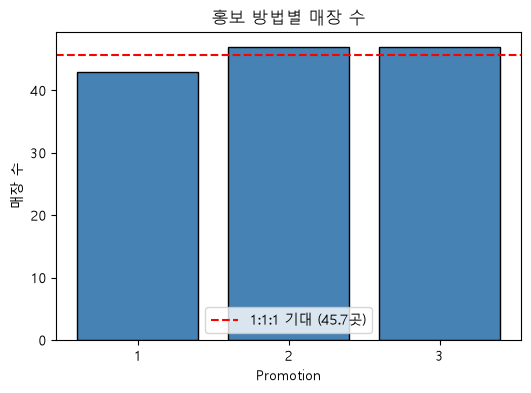

In [7]:
# 1줄: 홍보별 매장 수 (값마다 개수 → .value_counts(), 1·2·3 순서로)
n_store = stores["Promotion"].value_counts().sort_index()
# 2줄: 1:1:1일 때 기대 매장 수 (137 ÷ 3을 3번)
expected_n = [len(stores) / 3] * 3
# 3줄: 카이제곱 적합도 검정 (관찰, 기대)
srm = stats.chisquare(n_store.values, expected_n)
print(n_store)
print(f"기대 매장 수: {expected_n[0]:.2f}곳씩")
print(f"카이제곱 = {srm.statistic:.3f}, p = {srm.pvalue:.3f}")

# 4줄: 막대 + 기대선
plt.figure(figsize=(6, 4))
plt.bar(n_store.index.astype(str), n_store.values, color="steelblue", edgecolor="black")
plt.axhline(expected_n[0], color="red", linestyle="--", label=f"1:1:1 기대 ({expected_n[0]:.1f}곳)")
plt.title("홍보 방법별 매장 수")
plt.xlabel("Promotion")
plt.ylabel("매장 수")
plt.legend()
plt.show()

**결과:** 프로모션 1 = 43곳 · 2 = 47곳 · 3 = 47곳 · 기대 45.67곳씩 · 카이제곱 = 0.234 · p = 0.890

- 프로모션 1이 4곳 적지만, 1:1:1로 나눠도 이 정도 차이는 우연히 자주 생긴다(p = 0.890). 배정 비율 문제의 신호는 없다.
- 행 수(172 · 188 · 188행)가 아니라 배정 단위인 매장 수로 검정한다.

#### 1-7. 집단 균형과 설계 구조 — 시장 규모·시장·매장 나이

- 왜 필요한가: 매출이 높은 시장의 매장이 한 홍보에 몰렸다면, 그 홍보의 매출이 높아도 홍보 덕분이 아니라 시장 덕분일 수 있다(혼입).
- **교차표(pd.crosstab)** + **카이제곱 독립성 검정**: 두 범주가 서로 관계없다고 볼 수 있나. 칸마다 기대 개수 = 행 합 × 열 합 ÷ 전체 (예: Large × 1 = 42 × 43 ÷ 137 = 13.2곳). 기대 개수 5 미만 칸이 있으면 덜 정확하다.
- 시장(MarketID) × 홍보 교차표도 본다: 각 시장 안에 세 홍보가 섞여 있는지 = 이 실험이 "시장 안에서 매장을 나눠 배정한 구조"인지.
- 시장별 매출 수준(홍보 구분 없이)도 본다: 시장끼리 매출 수준이 크게 다르면, 그 차이가 홍보 비교의 잡음이 된다. 홍보별 매출이 아니라서 가설 전에 봐도 된다.

In [8]:
# 1줄: 시장 규모 × 홍보 교차표와 독립성 검정
size_by_promo = pd.crosstab(stores["MarketSize"], stores["Promotion"])
print(size_by_promo)
chi2_size, p_size, dof_size, exp_size = stats.chi2_contingency(size_by_promo)
print(f"카이제곱 = {chi2_size:.3f}, 자유도 = {dof_size}, p = {p_size:.3f}, 기대 5 미만 칸: {(exp_size < 5).sum()}개")

# 2줄: 시장(MarketID) × 홍보 교차표 — 시장마다 세 홍보가 섞여 있나
market_by_promo = pd.crosstab(stores["MarketID"], stores["Promotion"])
print(market_by_promo)

# 3줄: 시장별 매출 수준 (홍보 구분 없이 평균, 매장 수)
print(stores.groupby("MarketID")["avg_weekly_sales"].agg(["mean", "count"]).round(1))

# 4줄: 홍보별 매장 나이 요약
stores.groupby("Promotion")["AgeOfStore"].agg(["mean", "median", "min", "max"]).round(2)

Promotion    1   2   3
MarketSize            
Large       14  16  12
Medium      24  27  29
Small        5   4   6
카이제곱 = 1.188, 자유도 = 4, p = 0.880, 기대 5 미만 칸: 1개
Promotion  1   2  3
MarketID           
1          5   5  3
2          1   0  5
3          7   6  9
4          4   4  1
5          2   8  5
6          5   6  4
7          4   4  7
8          5   2  5
9          3   2  5
10         7  10  3
          mean  count
MarketID             
1         35.1     13
2         61.8      6
3         85.0     22
4         54.5      9
5         48.8     15
6         36.4     15
7         44.5     15
8         49.0     12
9         52.9     10
10        53.8     20


,mean,median,min,max
Promotion,,,,
1,8.28,6.0,1,27
2,7.98,7.0,1,28
3,9.23,8.0,1,24


**결과:** 시장 규모 × 홍보 카이제곱 = 1.188, 자유도 4, p = 0.880 (기대 5 미만 칸 1개) · 시장별 평균 매출 35.1 ~ 85.0 · 매장 나이 평균 8.28 · 7.98 · 9.23년

- 시장 규모: Large 14·16·12 / Medium 24·27·29 / Small 5·4·6. 특정 홍보에 쏠렸다고 볼 근거가 없다(p = 0.880). Small × 1 칸의 기대 개수 4.7이 5보다 작지만 p가 기준에서 아주 멀어 결론은 같다.
- 시장 × 홍보: 10개 시장 대부분에 세 홍보가 모두 있다. 예외는 시장 2(프로모션 2가 0곳)뿐이다. 즉 이 실험은 **시장마다 그 안의 매장을 세 홍보로 나눈 구조(블록 설계)**에 가깝다. 시장 안에서는 고르지 않은 곳도 있다(시장 4: 4·4·1곳, 시장 10: 7·10·3곳).
- 시장별 매출 수준: 시장 3이 85.0으로 가장 높고 시장 1이 35.1로 가장 낮다. 시장끼리 2배 넘게 차이 난다.
  - 이 차이는 홍보와 무관한 "시장 효과"다. 시장을 무시하고 홍보를 비교하면, 이 큰 차이가 전부 잡음으로 들어가 홍보 차이를 가린다.
  - 3단계에서 검정을 고를 때 이 구조를 반영한다.
- 매장 나이: 세 홍보 모두 1년부터 24~28년까지 퍼져 있고 평균 차이는 1.25년 이내다.

#### 1-판단 근거

1. 정제 전후: 548행 → 137행, 지운 행 0개. 4주를 매장 평균으로 합친 이유: 같은 매장의 4주 매출은 서로 비슷해서 독립이 아니므로.
2. SRM: 43 · 47 · 47곳, p = 0.890. 판단: 1:1:1 배정과 다르다고 보기 어렵다. 프로모션 1의 4곳 차이는 우연히 생길 수 있는 범위다.
3. 시장 규모 균형: p = 0.880. 이 결과가 중요한 이유: 시장 규모가 쏠리면 매출 차이가 홍보 때문인지 시장 때문인지 구분할 수 없어서.
4. 주차별 평균 53.21~53.79, 주차 간 상관 0.88~0.94, 매장 사이 몫 0.906. 이 숫자들이 4주 평균을 써도 된다는 근거인 이유: 주차에 따른 흐름이 없어 평균으로 합쳐도 잃는 정보가 적고, 같은 매장의 4주가 거의 같은 정보의 반복이라서.
   (보기: 주차에 따른 흐름이 없어 평균으로 합쳐도 잃는 정보가 적고, 같은 매장의 4주가 거의 같은 정보의 반복이라서 / 상관이 높을수록 매출이 높아서)
5. 시장별 평균 매출이 35.1~85.0으로 크게 다르다. 이 사실이 홍보 비교에 주는 문제: 시장 차이가 잡음으로 들어가 홍보 사이의 차이를 가릴 수 있다.
   (보기: 시장 차이가 잡음으로 들어가 홍보 사이의 차이를 가릴 수 있다 / 매출이 높은 시장은 데이터에서 빼야 한다)

#### 1-⚠️. 주의할 점

- **의도한 비율은 가정이다:** SRM을 1:1:1 기준으로 했지만 원 데이터 설명에 의도한 비율이 없다.
- **배정 방식을 모른다:** 시장 안에서 매장을 나눈 것으로 보이지만(1-7), 설명에 배정 절차가 없다. 시장 안 배정이 고르지 않은 곳(시장 4·10)이 있다.
- **균형 점검은 본 변수만:** 입지·주변 경쟁점처럼 데이터에 없는 특성의 균형은 확인할 수 없다.
- **기대 개수 5 미만 칸:** 시장 규모 검정의 p값은 근사치다.
- **매출 단위:** SalesInThousands는 천 달러다. 50 = 5만 달러.

### 2. 질문과 가설

한 줄 요약: 홍보별 매출을 보기 전에, 무엇을 알고 싶은지·무엇을 비교할지·어떤 기준과 분석으로 판단할지를 미리 정해 두고 끝까지 바꾸지 않는다.

#### 2-1. 알고 싶은 것 (질문 한 문장)

**질문:** 신메뉴 홍보 방법 3개 중, 매장의 평균 주간 매출이 홍보 방법에 따라 다른가? 다르다면 어느 홍보 방법이 가장 높은가?

- 성공 지표: 매장별 4주 평균 주간 매출 (avg_weekly_sales, 천 달러) — 1-5에서 만든 열
- 분석 단위: 매장 1곳 (137곳) · 비교 집단: Promotion 1 (43곳) · 2 (47곳) · 3 (47곳)
- 이 지표를 고른 이유: 체인이 알고 싶은 것이 "신메뉴가 얼마나 팔렸나"이고, 데이터에 있는 결과 변수가 매출 하나뿐이다.

#### 2-2. 귀무가설과 대립가설

- **귀무가설(H0)**: "차이가 없다"는 기본 입장. **대립가설(H1)**: 증거가 충분할 때 받아들이는 주장.
  - $H_0: \mu_1 = \mu_2 = \mu_3$ / $H_1:$ 적어도 한 홍보의 평균이 나머지와 다르다
  - $\mu$ = 모집단 평균 = "이 홍보를 모든 매장에 썼을 때의 평균 주간 매출"
- 흔한 실수: $H_1: \mu_1 \neq \mu_2 \neq \mu_3$. 이렇게 쓰면 "셋 다 서로 달라야 한다"가 된다. 실제 대립가설은 하나만 달라도 성립한다.

**H0 (문장):** 세 홍보 방법을 쓴 매장의 평균 주간 매출은 모두 같다.

**H1 (문장):** 세 홍보 방법 중 적어도 하나는 평균 주간 매출이 다르다.

- 전체 검정에서 H0를 기각하면 "어느 쌍이 다른가"를 본다 (1 vs 2, 1 vs 3, 2 vs 3). 쌍마다 H0: 같다 / H1: 다르다.

#### 2-3. 유의수준·방향·분석 계획

- **유의수준 α = 0.05**: 차이가 없을 때 100번 중 5번 정도 잘못 "있다"고 말하는 위험을 감수한다. 되돌릴 수 있는 마케팅 결정이라 더 엄격하게(0.01) 할 이유가 없다.
- **양측**: 어느 홍보가 이길지 미리 예상한 근거가 없다. 3집단 F 검정은 원래 방향이 없고, 쌍별 비교도 양측으로 한다.
- **분석 계획 (매출을 보기 전에 1단계의 설계 정보만으로 정함)**
  - 1-7에서 매장이 시장 10곳에 묶여 있고 시장마다 세 홍보가 섞여 있으며, 시장끼리 매출 수준이 2배 넘게 다르다는 것을 확인했다.
  - 그래서 홍보 비교에서 시장 차이를 함께 고려한다. 구체적인 검정은 3단계에서 가정을 점검한 뒤 고른다.
  - 노션 표의 기본 검정(시장을 무시한 일원 ANOVA)도 함께 보고해서, 시장을 고려했을 때 무엇이 달라지는지 비교한다.
- **판단 규칙**
  - 전체 검정 p < 0.05 → "홍보 방법에 따라 매출이 다르다" → 쌍별 비교(다중비교 보정)
  - p ≥ 0.05 → "차이가 있다는 증거가 부족하다" (차이가 없다는 증명이 아님)

In [9]:
# 1줄: 유의수준과 성공 지표를 상자에 담아 둠 (이후 모든 판단에서 이 상자를 씀, 대문자 = 바꾸지 않을 값)
ALPHA = 0.05
METRIC = "avg_weekly_sales"
print(f"성공 지표: {METRIC} (매장별 4주 평균 주간 매출, 천 달러)")
print(f"유의수준: {ALPHA}, 양측, 분석 단위: 매장 {len(stores)}곳")

성공 지표: avg_weekly_sales (매장별 4주 평균 주간 매출, 천 달러)
유의수준: 0.05, 양측, 분석 단위: 매장 137곳


**결과:** 성공 지표 avg_weekly_sales · 유의수준 0.05 · 양측 · 분석 단위 매장 137곳

#### 2-판단 근거

1. 가설을 데이터를 보기 전에 정한 이유: 결과를 본 뒤 가설을 바꾸면 우연한 차이도 유의하게 만들 수 있어서(p-해킹).
2. 대립가설을 "적어도 하나는 다르다"로 쓴 이유: 셋 중 하나만 달라도 홍보 방법에 따라 매출이 다르다고 말할 수 있어서.
3. 방향을 정하지 않은(양측) 이유: 어느 홍보가 더 높을지 미리 예상할 근거가 없어서.

#### 2-⚠️. 주의할 점

- **여기서 정한 것은 끝까지 유지한다:** 지표·유의수준·양측·"시장을 고려한다"는 계획을 결과를 본 뒤 바꾸지 않는다.
- **지표가 하나뿐이다:** 매출만 있고 이익·홍보 비용은 없다.
- **신메뉴 매출만 기록:** 다른 메뉴 매출이 줄었는지(대체 효과)는 알 수 없다.
- **4주:** 첫 4주의 효과다. 장기 효과는 말할 수 없다.
- **일반화 범위:** 이 체인의 이 10개 시장 결과다.

### 3. 검정 고르기

한 줄 요약: 노션의 세 질문(① 비율인가 연속형인가 ② 집단이 몇 개인가 ③ 정규성·등분산은 그럴듯한가)에 답하고, 1단계에서 본 설계 구조(시장 블록)를 더해 검정을 고른다.

#### 3-1. 지표 종류·집단 수 — 그리고 홍보별 분포 모양

- 질문 ① 지표: avg_weekly_sales = 34.42, 29.545처럼 이어지는 값 → **연속형**
- 질문 ② 집단: Promotion 1·2·3 → **3개** → 노션 표 "연속형 · 3집단 이상 → 일원 ANOVA → (유의하면) Tukey"
- 질문 ③을 보기 전에 분포 모양부터 그림으로 본다. 세 그림을 같은 축(sharex, sharey)으로 그려야 집단끼리 바로 비교된다.

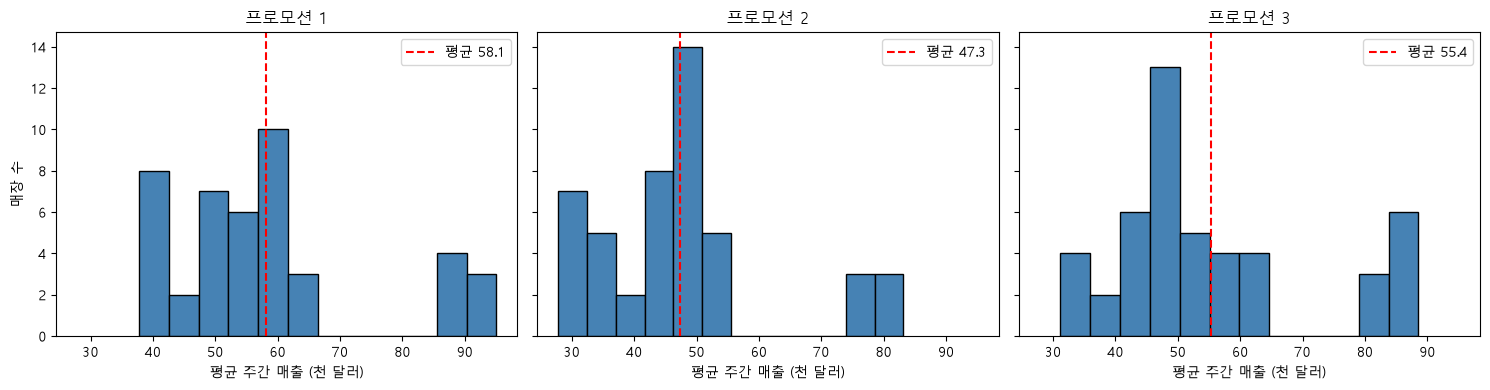

평균 주간 매출 75 이상 매장: 22곳
MarketID
3    22
Name: count, dtype: int64


In [10]:
# 1줄: 홍보별 평균 주간 매출 꺼내기 (행 고르기 → 열 꺼내기)
sales_p1 = stores[stores["Promotion"] == 1][METRIC]
sales_p2 = stores[stores["Promotion"] == 2][METRIC]
sales_p3 = stores[stores["Promotion"] == 3][METRIC]
groups = [sales_p1, sales_p2, sales_p3]
names = ["프로모션 1", "프로모션 2", "프로모션 3"]

# 2줄: 1행 3칸 히스토그램 (zip = 칸·자료·이름을 한 묶음씩 짝지어 꺼냄)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, sales, name in zip(axes, groups, names):
    ax.hist(sales, bins=12, color="steelblue", edgecolor="black")
    ax.axvline(sales.mean(), color="red", linestyle="--", label=f"평균 {sales.mean():.1f}")
    ax.set_title(name)
    ax.set_xlabel("평균 주간 매출 (천 달러)")
    ax.legend()
axes[0].set_ylabel("매장 수")
plt.tight_layout()
plt.show()

# 3줄: 오른쪽 끝 덩어리 확인 — 75 이상 매장이 어느 시장에 있나
high_sales = stores[stores[METRIC] >= 75]
print(f"평균 주간 매출 75 이상 매장: {len(high_sales)}곳")
print(high_sales["MarketID"].value_counts())

**결과:** 평균 58.1 · 47.3 · 55.4 · 75 이상 매장 22곳 = 전부 시장 3

- 세 히스토그램 모두 종 모양 하나가 아니다. 왼쪽 큰 덩어리와 오른쪽 끝 작은 덩어리(약 74~95) 사이가 비어 있다.
- 오른쪽 덩어리 22곳은 모두 시장 3(평균 85.0)의 매장이다. 두 봉우리는 홍보 때문이 아니라 **매출이 유독 높은 시장이 섞여서**다.
- 시장 3 매장은 세 홍보에 7 · 6 · 9곳으로 나뉘어 있다(1-7 교차표). 오류가 아니라 실제로 매출이 높은 시장이므로 지우지 않는다.

#### 3-2. 정규성 — 집단별, 그리고 시장을 뺀 나머지(잔차)

- **Q-Q plot**: 데이터를 작은 값부터 줄 세운 것(세로)과 정규분포였다면 그 순서에 있어야 할 값(가로)을 점으로 찍은 그림. 정규면 점이 직선 위에 놓인다.
- **Shapiro-Wilk**: H0 = "정규분포에서 왔다". p < 0.05면 정규성 기각. SRM처럼 p가 커야 "괜찮다"는 쪽이다.
- **잔차**: 모형이 설명하고 남은 부분 = 실제 값 − 모형이 예측한 값. ANOVA의 정규성 가정은 원래 "잔차가 정규"다.
  - 시장을 무시하면 잔차 = 매장 매출 − 홍보 평균 → 시장 차이가 잔차에 그대로 남는다.
  - 시장을 고려하면 잔차 = 매장 매출 − (홍보 효과 + 시장 효과) → 시장 차이가 빠진다.
- **선형 모형 식 `smf.ols("매출 ~ C(Promotion) + C(MarketID)")`**: 매출을 "홍보 몫 + 시장 몫 + 나머지"로 나누는 식. `C( )` = 숫자가 아니라 범주로 다루라는 표시 (설문의 더미변수 회귀와 같다).

프로모션 1: W = 0.868, p = 0.0002, 정규성 기각: True
프로모션 2: W = 0.849, p = 0.0000, 정규성 기각: True
프로모션 3: W = 0.876, p = 0.0001, 정규성 기각: True


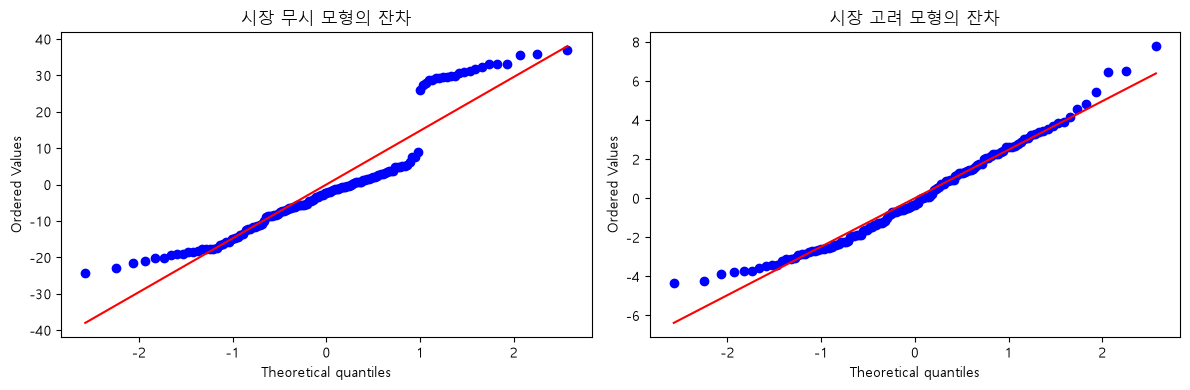

시장 무시 잔차: W = 0.879, p = 0.0000, 잔차 표준편차 = 15.65
시장 고려 잔차: W = 0.973, p = 0.0076, 잔차 표준편차 = 2.59


In [11]:
# 1줄: 집단별 Shapiro-Wilk
for sales, name in zip(groups, names):
    sw = stats.shapiro(sales)
    print(f"{name}: W = {sw.statistic:.3f}, p = {sw.pvalue:.4f}, 정규성 기각: {sw.pvalue < ALPHA}")

# 2줄: 시장을 무시한 모형과 시장을 고려한 모형
model_oneway = smf.ols(f"{METRIC} ~ C(Promotion)", data=stores).fit()
model_block = smf.ols(f"{METRIC} ~ C(Promotion) + C(MarketID)", data=stores).fit()

# 3줄: 두 모형의 잔차 Q-Q plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats.probplot(model_oneway.resid, dist="norm", plot=axes[0])
axes[0].set_title("시장 무시 모형의 잔차")
stats.probplot(model_block.resid, dist="norm", plot=axes[1])
axes[1].set_title("시장 고려 모형의 잔차")
plt.tight_layout()
plt.show()

# 4줄: 잔차 Shapiro-Wilk와 잔차 표준편차
for label, model in [("시장 무시", model_oneway), ("시장 고려", model_block)]:
    sw = stats.shapiro(model.resid)
    print(f"{label} 잔차: W = {sw.statistic:.3f}, p = {sw.pvalue:.4f}, 잔차 표준편차 = {np.sqrt(model.mse_resid):.2f}")

**결과:** 집단별 Shapiro p = 0.0002 · 0.0000 · 0.0001 (모두 기각) · 시장 무시 잔차 W = 0.879, p = 0.0000, 잔차 표준편차 15.65 · 시장 고려 잔차 W = 0.973, p = 0.0076, 잔차 표준편차 2.59

- 시장을 무시하면 잔차 Q-Q plot의 오른쪽 위가 계단처럼 튀어 오른다(시장 3 덩어리). 정규성이 크게 깨진다.
- 시장을 고려하면 Q-Q 점들이 직선에 훨씬 가깝게 붙는다. W가 0.879 → 0.973으로 1에 가까워졌다. p = 0.0076으로 아직 기각되지만, 어긋남은 작다(137곳이면 작은 어긋남도 기각된다).
- 가장 큰 변화는 잔차 표준편차다: **15.65 → 2.59**. 시장을 무시하면 매장 사이 퍼짐의 대부분이 시장 차이였다는 뜻이다. 홍보 차이를 재는 "잡음 기준"이 6분의 1로 줄어든다.

#### 3-3. 등분산 — 세 집단의 퍼짐이 비슷한가

- ANOVA는 집단 안의 퍼짐을 한데 모아 "기준 잡음"으로 쓴다. 한 집단만 유독 퍼져 있으면 기준이 틀어진다.
- 대략 규칙: 가장 큰 표준편차 ÷ 가장 작은 표준편차 < 2면 큰 문제 없음.
- **Levene 검정**: H0 = "분산이 같다". 정규성이 깨져도 비교적 믿을 만하다. 원 매출과 시장 고려 잔차 둘 다 본다.

In [12]:
# 1줄: 홍보별 표준편차와 비율
sd_by_promo = stores.groupby("Promotion")[METRIC].std()
print(sd_by_promo.round(2))
print(f"최대 ÷ 최소 = {sd_by_promo.max() / sd_by_promo.min():.2f}")

# 2줄: 원 매출의 Levene
lev = stats.levene(*groups)
print(f"원 매출 Levene: 통계량 = {lev.statistic:.3f}, p = {lev.pvalue:.3f}")
# 3줄: 시장 고려 잔차의 Levene (홍보별로 잔차를 나눠 넣음)
resid_groups = [model_block.resid[stores["Promotion"] == p] for p in [1, 2, 3]]
lev_resid = stats.levene(*resid_groups)
print(f"시장 고려 잔차 Levene: 통계량 = {lev_resid.statistic:.3f}, p = {lev_resid.pvalue:.3f}")

Promotion
1    16.03
2    14.50
3    16.38
Name: avg_weekly_sales, dtype: float64
최대 ÷ 최소 = 1.13
원 매출 Levene: 통계량 = 0.468, p = 0.627
시장 고려 잔차 Levene: 통계량 = 1.318, p = 0.271


**결과:** 표준편차 16.03 · 14.50 · 16.38 · 최대 ÷ 최소 = 1.13 · 원 매출 Levene p = 0.627 · 시장 고려 잔차 Levene p = 0.271

- 두 경우 모두 "분산이 다르다"고 볼 근거가 없다. 등분산 가정은 괜찮다.

#### 3-4. 검정 결정 — 주 분석: 시장을 블록으로 넣은 이원 분산분석

- 지금까지 답: ① 연속형 ② 3집단 ③ 정규성: 시장 무시하면 크게 깨짐 / 시장 고려하면 거의 정규 · 등분산: 괜찮음
- 노션 표의 기본 답은 **일원 ANOVA**다. 그런데 이 데이터는 1-7에서 본 대로 "시장마다 매장을 세 홍보로 나눈" 블록 구조이고, 시장 차이가 매출 퍼짐의 대부분을 차지한다.
- **이원 분산분석 (블록 설계)**: 매출을 "홍보 몫 + 시장 몫 + 나머지"로 나눈 뒤, 홍보 몫이 나머지(잡음)에 비해 큰지 본다.
  - $F_{\text{홍보}} = \frac{\text{홍보 제곱합} / 2}{\text{잔차 제곱합} / \text{잔차 자유도}}$
  - 일원 ANOVA와 분자는 비슷하지만, 분모(잡음)에서 시장 차이가 빠져서 훨씬 작아진다.
  - 비유: 지역마다 소득 수준이 다른 응답자들에게 설문 문항 A·B·C를 무작위로 보여 줬다면, 지역을 통제 변수로 넣고 문항 효과를 보는 것과 같다. 설문 분석의 "통제 변수를 넣은 회귀"다.
- 그래서 고른 검정
  - **주 분석: 이원 분산분석 (홍보 + 시장)** → 유의하면 홍보 쌍별 비교 (Bonferroni 보정)
  - 비교 분석: 일원 ANOVA + Tukey (노션 표 기본) — 시장을 고려했을 때 무엇이 달라지는지 보여 주기 위해
  - 가정 확인: 시장 고려 잔차도 정규성이 약간 어긋나므로, 정규성을 가정하지 않는 방법(순위 검정·시장별 부호 검정)으로 결론이 같은지 확인 → 5단계 B
- 이 선택은 2-3에서 매출을 보기 전에 정한 계획("시장 차이를 함께 고려한다")을 따른 것이다. 시장 구조는 1단계의 설계 정보(교차표·시장별 매출 수준)로 알았고, 홍보별 결과를 보고 고른 것이 아니다.

#### 3-판단 근거 (검정 선택 문단)

나는 시장을 블록으로 넣은 이원 분산분석을 주 검정으로 골랐다.
1. 지표와 집단: 성공 지표가 연속형(매장별 평균 주간 매출)이고 비교할 집단이 3개라서, 노션 표로는 일원 ANOVA에 해당한다.
2. 그런데 이 데이터에서 시장을 함께 넣은 이유: 시장마다 매장을 세 홍보로 나눈 구조이고 시장 차이가 매출 퍼짐의 대부분이라, 시장을 빼면 그 차이가 잡음이 되어 홍보 차이를 가리기 때문.
   (보기: 시장마다 매장을 세 홍보로 나눈 구조이고 시장 차이가 매출 퍼짐의 대부분이라, 시장을 빼면 그 차이가 잡음이 되어 홍보 차이를 가리기 때문 / 시장 3의 매출이 너무 높아서 지우기 위해)
3. 가정 점검: 시장을 고려하면 잔차 표준편차가 15.65 → 2.59로 줄고 Q-Q가 직선에 가까워진다(W 0.879 → 0.973). 등분산은 Levene p = 0.627(원 매출), 0.271(잔차)로 괜찮다.
4. 보완: 잔차 정규성이 아직 약간 어긋나므로 정규성을 가정하지 않는 순위 검정과 시장별 부호 검정으로 결론이 같은지 확인한다.
   (보기: 정규성을 가정하지 않는 순위 검정과 시장별 부호 검정 / 시장 3을 지운 데이터)

#### 3-⚠️. 주의할 점

- **노션 표 밖의 선택:** 이원 분산분석은 노션 표에 없는 검정이다. 표의 기본(일원 ANOVA)을 함께 보고해서, 고른 이유가 결과를 바꾸기 위한 것이 아님을 투명하게 보인다.
- **시장 효과는 "더하기"로 가정:** 이원 분산분석(상호작용 없음)은 "홍보 효과가 모든 시장에서 같은 크기"라고 가정한다. 5-3에서 확인한다.
- **시장 2에 프로모션 2가 없다:** 시장 2의 매장은 1 vs 3 비교에만 정보를 준다.
- **Shapiro-Wilk의 한계:** 표본이 크면 작은 어긋남도 기각한다. 그래서 그림(Q-Q)과 함께 판단한다.

### 4. 검정 수행과 3종 세트

한 줄 요약: 비교용 일원 ANOVA와 주 분석인 이원 분산분석을 수행하고, p값 하나로 끝내지 않고 차이(점추정) · 95% 신뢰구간 · 효과 크기를 함께 보고한다.

#### 4-1. 비교용: 일원 ANOVA (시장 무시)와 효과 크기 η²

- $F = \frac{\text{집단 사이 제곱합} / (k-1)}{\text{집단 안 제곱합} / (N-k)}$ (k = 3, N = 137 → F(2, 134))
- **η² (에타 제곱)** = 집단 사이 제곱합 ÷ 전체 제곱합 = 매출 차이 중 몇 %가 홍보로 설명되나. 기준(대략): 0.01 작음 · 0.06 중간 · 0.14 큼. 회귀의 R²와 같다.
- p값은 "우연인가", η²는 "얼마나 큰가"에 답한다.

In [13]:
# 1줄: 일원 ANOVA
anova_oneway = stats.f_oneway(*groups)
k, n_total = 3, len(stores)

# 2줄: 손계산용 제곱합 — 전체 평균, 집단 사이, 전체, 집단 안
grand_mean = stores[METRIC].mean()
ss_between = sum(len(s) * (s.mean() - grand_mean) ** 2 for s in groups)
ss_total = ((stores[METRIC] - grand_mean) ** 2).sum()
ss_within = ss_total - ss_between
# 3줄: 평균제곱 = 제곱합 ÷ 자유도, F = 사이 ÷ 안
ms_between = ss_between / (k - 1)
ms_within = ss_within / (n_total - k)
print(f"집단 사이 제곱합 = {ss_between:.1f}, 집단 안 제곱합 = {ss_within:.1f}, 전체 = {ss_total:.1f}")
print(f"손계산 F = {ms_between:.1f} ÷ {ms_within:.1f} = {ms_between / ms_within:.2f}")
print(f"scipy F({k - 1}, {n_total - k}) = {anova_oneway.statistic:.2f}, p = {anova_oneway.pvalue:.4f}")
print(f"η² = {ss_between / ss_total:.3f}")

집단 사이 제곱합 = 2862.3, 집단 안 제곱합 = 32805.4, 전체 = 35667.7
손계산 F = 1431.1 ÷ 244.8 = 5.85
scipy F(2, 134) = 5.85, p = 0.0037
η² = 0.080


**결과:** 집단 사이 제곱합 2862.3 · 집단 안 32805.4 · 전체 35667.7 · F = 1431.1 ÷ 244.8 = 5.85 · F(2, 134) = 5.85, p = 0.0037 · η² = 0.080

- 시장을 무시해도 p = 0.0037 < 0.05 → 세 홍보 중 적어도 하나는 매출이 다르다.
- η² = 0.080 → 매출 차이의 8%만 홍보로 설명된다. 나머지 92%(집단 안 제곱합 32805.4)의 대부분은 1-7·3-2에서 본 시장 차이다.
- 분모(집단 안 평균제곱 244.8)가 크다. 시장 차이가 "잡음"에 들어가 있기 때문이다 → 4-2에서 이 잡음을 뺀다.

#### 4-2. 주 분석: 이원 분산분석 (홍보 + 시장 블록)과 부분 η²

- `sm.stats.anova_lm(model_block, typ=2)`: 3-2에서 만든 시장 고려 모형의 분산분석표. 행마다 제곱합(sum_sq) · 자유도(df) · F · p(PR(>F)).
  - typ=2 = "다른 요인을 고려한 뒤 그 요인이 더 설명하는 몫". 시장마다 매장 수가 달라서(불균형) 쓰는 방식이다.
- **부분 η²** = 홍보 제곱합 ÷ (홍보 제곱합 + 잔차 제곱합) = 시장 차이를 뺀 나머지 퍼짐 중 홍보가 설명하는 몫.

In [14]:
# 1줄: 이원 분산분석표
anova_block = sm.stats.anova_lm(model_block, typ=2)
print(anova_block.round(4))

# 2줄: 손계산 F (홍보) = (홍보 제곱합 ÷ 2) ÷ (잔차 제곱합 ÷ 잔차 자유도)
ss_promo = anova_block.loc["C(Promotion)", "sum_sq"]
ss_resid = anova_block.loc["Residual", "sum_sq"]
df_resid = anova_block.loc["Residual", "df"]
print(f"손계산 F = ({ss_promo:.1f} ÷ 2) ÷ ({ss_resid:.1f} ÷ {df_resid:.0f}) = {(ss_promo / 2) / (ss_resid / df_resid):.2f}")
print(f"홍보 p = {anova_block.loc['C(Promotion)', 'PR(>F)']:.2e}")
# 3줄: 부분 η²
print(f"부분 η² (홍보) = {ss_promo / (ss_promo + ss_resid):.3f}")

                  sum_sq     df         F  PR(>F)
C(Promotion)   2031.2608    2.0  151.2538     0.0
C(MarketID)   31966.0789    9.0  528.9535     0.0
Residual        839.3428  125.0       NaN     NaN
손계산 F = (2031.3 ÷ 2) ÷ (839.3 ÷ 125) = 151.25
홍보 p = 4.20e-34
부분 η² (홍보) = 0.708


**결과:** 홍보 제곱합 2031.3 · 시장 제곱합 31966.1 · 잔차 제곱합 839.3 (자유도 125) · F(홍보) = (2031.3 ÷ 2) ÷ (839.3 ÷ 125) = 1015.6 ÷ 6.7 = 151.25 · p = 4.20e-34 · 시장 F = 528.95 · 부분 η² = 0.708

- 시장을 고려하면 홍보 효과가 압도적으로 뚜렷하다. F가 5.85 → 151.25, p가 0.0037 → 4.2 × 10⁻³⁴.
- 이유는 분자가 아니라 분모다. 홍보 몫(2862.3 → 2031.3)은 비슷한 크기인데, 잡음(평균제곱 244.8 → 6.7)이 시장 차이가 빠지면서 약 36분의 1로 줄었다.
- 시장 제곱합 31966.1은 매출 퍼짐의 대부분이 시장 차이라는 것을 숫자로 보여 준다(1-7 시장별 평균 35.1~85.0).
- 부분 η² = 2031.3 ÷ (2031.3 + 839.3) = 0.708 → 시장 차이를 빼고 나면, 매장끼리의 매출 차이 중 71%가 홍보로 설명된다.
- 4-1의 η² 0.080과 부분 η² 0.708은 분모가 다르다(전체 퍼짐 vs 시장을 뺀 퍼짐). 둘을 직접 비교하면 안 되고, 보고할 때 어느 것인지 밝힌다.

#### 4-3. 점추정과 95% 신뢰구간 — 홍보별 평균 주간 매출

- **표준오차(SE)** = $s / \sqrt{n}$. 프로모션 1: 16.03 ÷ √43 = 16.03 ÷ 6.56 = 2.44
- **95% 신뢰구간** = 평균 ± t값 × SE (t값 = 자유도 n − 1에서 가운데 95%, 43곳이면 약 2.02)
- 막대 위에 신뢰구간을 오차 막대로 그린다. 이 구간은 시장 차이가 모두 들어간 원 매출 기준이다.

           count   mean    std    se  ci_low  ci_high
Promotion                                            
1             43  58.10  16.03  2.44   53.17    63.03
2             47  47.33  14.50  2.11   43.07    51.59
3             47  55.36  16.38  2.39   50.55    60.17


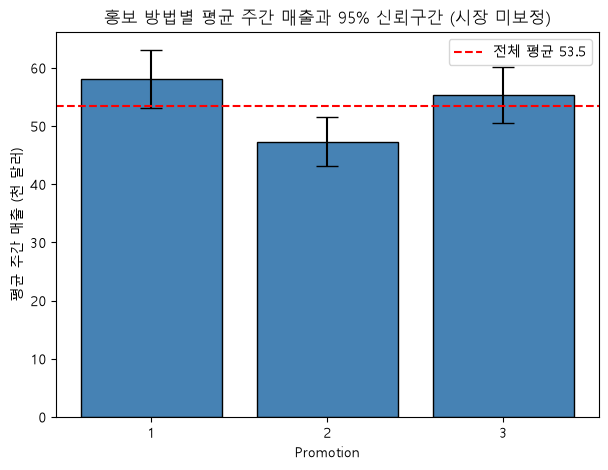

In [15]:
# 1줄: 홍보별 매장 수 · 평균 · 표준편차 · 표준오차
summary = stores.groupby("Promotion")[METRIC].agg(["count", "mean", "std"])
summary["se"] = summary["std"] / np.sqrt(summary["count"])
# 2줄: 95% t값과 구간
t_crit = stats.t.ppf(0.975, summary["count"] - 1)
summary["ci_low"] = summary["mean"] - t_crit * summary["se"]
summary["ci_high"] = summary["mean"] + t_crit * summary["se"]
print(summary.round(2))

# 3줄: 평균 막대 + 신뢰구간 오차 막대 + 전체 평균선
plt.figure(figsize=(7, 5))
plt.bar(summary.index.astype(str), summary["mean"], yerr=t_crit * summary["se"],
        capsize=8, color="steelblue", edgecolor="black")
plt.axhline(grand_mean, color="red", linestyle="--", label=f"전체 평균 {grand_mean:.1f}")
plt.title("홍보 방법별 평균 주간 매출과 95% 신뢰구간 (시장 미보정)")
plt.xlabel("Promotion")
plt.ylabel("평균 주간 매출 (천 달러)")
plt.legend()
plt.show()

**결과:** 프로모션 1 = 58.10 (95% CI 53.17~63.03) · 2 = 47.33 (43.07~51.59) · 3 = 55.36 (50.55~60.17)

- 매장당 평균 주간 신메뉴 매출: 1 ≈ 5만 8천 달러, 2 ≈ 4만 7천 달러, 3 ≈ 5만 5천 달러. 막대는 0부터 그렸다.
- 1과 3의 구간이 크게 겹친다. 그러나 이 구간에는 시장 차이(잡음)가 다 들어 있어서 넓다. 쌍별 차이는 4-4에서 시장을 고려해 본다.

#### 4-4. 쌍별 비교 — 시장 무시(Tukey) vs 시장 고려(Bonferroni)

- **Tukey HSD (`pairwise_tukeyhsd`)**: 일원 ANOVA 뒤 세 쌍을 비교하며 여러 번 비교한 위험을 보정한다. 표의 meandiff = group2 − group1.
- **시장 고려 쌍별 비교 (`t_test_pairwise`)**: 이원 분산분석 모형에서 홍보 두 개의 차이를 시장을 고려해 추정하고, Bonferroni로 보정한다(p × 3). 표의 coef = 앞 번호 − 뒤 번호 (예: 2-1 = 프로모션 2 − 프로모션 1).
- 3종 세트
  - ① 점추정: 평균 차이 (천 달러)와 상대 차이 (%) — 둘 다 적어야 과장도 축소도 없다
  - ② 95% 신뢰구간
  - ③ 효과 크기 **Cohen's d** = 차이 ÷ 합동 표준편차. 0.2 작음 · 0.5 중간 · 0.8 큼
    - $s_p = \sqrt{\frac{\sum (n_i - 1) s_i^2}{N - k}}$ = 15.65 (시장 차이가 들어 있는 매장 사이 퍼짐)
    - 예: 1 − 2 = 10.77 ÷ 15.65 = 0.69
    - 시장 고려 차이도 같은 15.65로 나눠서 "매장 사이 전체 퍼짐에 비해 얼마나 큰가"로 통일한다. 잔차 표준편차(2.59)로 나누면 d가 커 보이지만 해석 기준이 달라진다.

In [16]:
# 1줄: 시장 무시 — Tukey HSD
tukey = pairwise_tukeyhsd(stores[METRIC], stores["Promotion"], alpha=ALPHA)
print(tukey.summary())

# 2줄: 시장 고려 — 이원 분산분석 모형에서 쌍별 비교 (Bonferroni 보정)
pairwise_block = model_block.t_test_pairwise("C(Promotion)", method="bonferroni").result_frame
print(pairwise_block[["coef", "Conf. Int. Low", "Conf. Int. Upp."]].round(4))
print(pairwise_block["pvalue-bonferroni"].map("{:.1e}".format))

# 3줄: 합동 표준편차 (Cohen's d의 분모)
pooled_sd = np.sqrt(((summary["count"] - 1) * summary["std"] ** 2).sum() / (n_total - k))
print(f"합동 표준편차 = {pooled_sd:.2f}")

# 4줄: 보기 좋게 한 표로 (시장 무시 차이 / 시장 고려 차이 / 상대 차이 / d)
#      시장 고려 표는 "2-1", "3-1", "3-2" 이름이라 1 − 2 = −(2-1)처럼 부호를 맞춤
rows = []
for a, b, key, sign in [(1, 2, "2-1", -1), (1, 3, "3-1", -1), (3, 2, "3-2", 1)]:
    raw_diff = summary.loc[a, "mean"] - summary.loc[b, "mean"]
    adj_diff = sign * pairwise_block.loc[key, "coef"]
    adj_low, adj_high = sorted([sign * pairwise_block.loc[key, "Conf. Int. Low"], sign * pairwise_block.loc[key, "Conf. Int. Upp."]])
    rows.append({"비교": f"{a} − {b}",
                 "시장 무시 차이": raw_diff,
                 "상대 차이(%)": raw_diff / summary.loc[b, "mean"] * 100,
                 "d (시장 무시)": raw_diff / pooled_sd,
                 "시장 고려 차이": adj_diff,
                 "시장 고려 95% CI": f"{adj_low:.2f} ~ {adj_high:.2f}",
                 "시장 고려 p (보정)": pairwise_block.loc[key, "pvalue-bonferroni"],
                 "d (시장 고려)": adj_diff / pooled_sd})
pair_table = pd.DataFrame(rows)

# 5줄: 확인 — 매장이 속한 시장의 평균 매출을 홍보별로 (어느 홍보가 매출 높은 시장에 몰렸나)
market_level = stores.groupby("MarketID")[METRIC].transform("mean")
print(market_level.groupby(stores["Promotion"]).mean().round(2))
pair_table.round(3)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2 -10.7696  0.004 -18.5951  -2.944   True
     1      3  -2.7345 0.6862 -10.5601   5.091  False
     2      3   8.0351 0.0371   0.3854 15.6847   True
-----------------------------------------------------
       coef  Conf. Int. Low  Conf. Int. Upp.
2-1 -9.7180        -10.8240          -8.6121
3-1 -4.9249         -6.0485          -3.8013
3-2  4.7931          3.6640           5.9222
2-1    1.1e-34
3-1    5.6e-14
3-2    2.5e-13
Name: pvalue-bonferroni, dtype: str
합동 표준편차 = 15.65
Promotion
1    53.20
2    51.74
3    55.43
Name: avg_weekly_sales, dtype: float64


,비교,시장 무시 차이,상대 차이(%),d (시장 무시),시장 고려 차이,시장 고려 95% CI,시장 고려 p (보정),d (시장 고려)
0,1 − 2,10.770,22.755,0.688,9.718,8.61 ~ 10.82,0.0,0.621
1,1 − 3,2.735,4.939,0.175,4.925,3.80 ~ 6.05,0.0,0.315
2,3 − 2,8.035,16.977,0.514,4.793,3.66 ~ 5.92,0.0,0.306


**결과:** 합동 표준편차 15.65

| 비교 | 시장 무시 차이 | 상대 차이 | Tukey 95% CI | Tukey p | d | 시장 고려 차이 | 시장 고려 95% CI | 보정 p | d |
|---|---|---|---|---|---|---|---|---|---|
| 1 − 2 | +10.77 | +22.8% | 2.94 ~ 18.60 | 0.004 | 0.69 | +9.72 | 8.61 ~ 10.82 | 1.1e-34 | 0.62 |
| 1 − 3 | +2.73 | +4.9% | −5.09 ~ 10.56 | 0.686 | 0.17 | +4.92 | 3.80 ~ 6.05 | 5.6e-14 | 0.31 |
| 3 − 2 | +8.04 | +17.0% | 0.39 ~ 15.68 | 0.037 | 0.51 | +4.79 | 3.66 ~ 5.92 | 2.5e-13 | 0.31 |

- Tukey 표(statsmodels)는 meandiff = group2 − group1로 나온다(예: 1, 2 행 = −10.77 → 1이 10.77 높다). 위 표는 모두 "앞 − 뒤"로 맞췄다.
- 시장을 무시하면: 2가 1·3보다 낮고, **1과 3은 구분되지 않는다**(p = 0.686, 구간이 0 포함).
- 시장을 고려하면: **1 > 3 > 2가 모두 뚜렷하다.** 1이 3보다 매장당 주 4.92천 달러 높고, 구간 3.80~6.05가 0에서 멀다.
- 왜 결론이 바뀌나: 1 − 3 차이를 재는 잣대(잡음)가 다르다. 시장 무시 구간 폭 약 15.6 vs 시장 고려 폭 약 2.3. 같은 137곳인데 시장 차이를 빼자 1 − 3의 차이가 잡음 위로 드러났다.
- 시장 고려 1 − 3 차이(4.92)가 시장 무시 차이(2.73)보다 크다. 프로모션 3의 매장이 매출이 높은 시장에 조금 더 몰려 있어서(매장이 속한 시장의 평균 매출: 1 = 53.20, 2 = 51.74, 3 = 55.43), 단순 평균이 3을 실제보다 좋아 보이게 했다. 시장을 고려하면 이 유리함이 빠진다.
- 크기 해석 (d, 매장 사이 전체 퍼짐 기준): 1 − 2 = 0.62 중간, 1 − 3 · 3 − 2 = 0.31 작음~중간. 즉 "확실한 차이"지만 매장 사이 매출 차이에 비하면 크지 않다. 실무 판단은 천 달러 차이로 한다.

#### 4-5. 보고 문장

시장을 블록으로 넣은 이원 분산분석에서 홍보 방법에 따라 매장당 평균 주간 신메뉴 매출이 달랐다(F(2, 125) = 151.25, p < .001, 부분 η² = 0.71).
시장을 고려했을 때 프로모션 1은 프로모션 3보다 주 +4.9천 달러(95% CI 3.8 ~ 6.0, Bonferroni p < .001, d = 0.31), 프로모션 2보다 주 +9.7천 달러(95% CI 8.6 ~ 10.8, p < .001, d = 0.62) 높았고, 프로모션 3은 2보다 +4.8천 달러(95% CI 3.7 ~ 5.9, p < .001, d = 0.31) 높았다.
시장을 무시한 일원 ANOVA(F(2, 134) = 5.85, p = .004, η² = 0.08)에서는 1과 3의 차이(+2.7천 달러, +4.9%)가 유의하지 않았다(Tukey p = .686). 시장 차이가 잡음으로 들어가 1 − 3 차이를 가렸기 때문이다.

#### 4-판단 근거

1. 일원 ANOVA η² = 0.080, 이원 분산분석 부분 η² = 0.708. 두 숫자를 직접 비교하면 안 되는 이유: 분모가 다르다 — 하나는 전체 퍼짐, 하나는 시장 차이를 뺀 퍼짐.
   (보기: 분모가 다르다 — 하나는 전체 퍼짐, 하나는 시장 차이를 뺀 퍼짐 / 이원 분산분석이 계산을 잘못해서)
2. 1 − 3이 시장 무시에서는 p = 0.686, 시장 고려에서는 p < .001이 된 이유: 시장 차이가 잡음에서 빠져 같은 차이를 재는 잣대가 약 15.6 → 2.3 폭으로 좁아졌기 때문.
   (보기: 시장 차이가 잡음에서 빠져 같은 차이를 재는 잣대가 약 15.6 → 2.3 폭으로 좁아졌기 때문 / 시장을 고려하면 홍보 효과 자체가 커지기 때문)
3. 시장 무시 일원 ANOVA를 버리지 않고 함께 보고한 이유:  노션 표의 기본 검정과 비교해서, 시장을 고려한 선택이 무엇을 바꿨는지 투명하게 보이려고.
   (보기: 노션 표의 기본 검정과 비교해서, 시장을 고려한 선택이 무엇을 바꿨는지 투명하게 보이려고 / p값이 더 작은 쪽을 고르려고)

#### 4-⚠️. 주의할 점

- **유의 ≠ 중요:** 1 − 3 차이 주 4.9천 달러가 홍보 비용 차이보다 큰지는 비용 데이터가 없어 판단할 수 없다.
- **"더하기" 가정:** 이원 분산분석은 홍보 효과가 시장마다 같다고 가정한다 → 5-3에서 확인.
- **잔차 정규성이 약간 어긋난다(p = 0.0076):** 5단계에서 순위 검정·부호 검정으로 확인한다.
- **효과 크기 기준을 밝힌다:** d는 매장 사이 전체 퍼짐(15.65)으로 나눴다. 잔차 표준편차(2.59)로 나누면 d = 1.9처럼 커 보인다.
- **인과의 근거는 무작위 배정:** 시장 안에서 매장이 무작위로 배정되었다는 가정 위에서 "홍보가 매출을 바꿨다"고 말할 수 있다.

### 5. 한 걸음 더 — B. 가정이 깨졌다면 + A. 이 실험은 효과를 잡을 힘이 있었나

한 줄 요약: (B) 정규성을 가정하지 않는 방법과 "시장마다 같은 방향인가"로 4단계 결론을 확인하고, (A) 시장을 무시할 때와 고려할 때 이 실험이 잡을 수 있는 가장 작은 차이(MDE)를 비교해서 4단계에서 결론이 갈린 이유를 숫자로 설명한다.

- B를 깊게 고른 이유: 이 데이터의 가장 큰 약점이 정규성 위반(시장 덩어리)이라서.
- A를 더한 이유: 시장 무시 분석에서 1 vs 3이 "구분 안 됨"이었다. 노션 말대로 "효과가 없다"와 "확인할 힘이 없었다"를 구분하려면 MDE가 필요하다.

#### 5-1. 순위 검정 — Kruskal-Wallis와 Mann-Whitney U (multipletests 보정)

- **Kruskal-Wallis**: 137곳을 매출 순으로 줄 세운 뒤 세 홍보의 평균 순위가 비슷한지 본다. 정규성을 가정하지 않는다(순위로 하는 일원 ANOVA).
- **Mann-Whitney U**: 두 집단을 섞어 순위를 매긴 뒤 한쪽이 위쪽에 몰려 있는지 본다(2집단판).
- **`multipletests(p값 목록, method="bonferroni")`**: 비교를 3번 하므로 p × 3(1을 넘으면 1). 9-10장 문제 3의 보정 도구.
  - 예: 3 − 2 t 검정 p = 0.0135 → 0.0135 × 3 = 0.0406
- 이 검정들은 시장을 무시한다. 시장 덩어리에 흔들리지 않는지(순위라서) 보는 용도다.

In [17]:
# 1줄: Kruskal-Wallis
kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {kw.statistic:.2f}, p = {kw.pvalue:.4f}")
print(stores.groupby("Promotion")[METRIC].median().round(2))

# 2줄: 쌍별 t 검정과 Mann-Whitney U의 p값 모으기
pairs = [(0, 1), (0, 2), (2, 1)]
pair_names = [f"{names[i]} − {names[j]}" for i, j in pairs]
t_pvals = [stats.ttest_ind(groups[i], groups[j]).pvalue for i, j in pairs]
u_pvals = [stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided").pvalue for i, j in pairs]

# 3줄: multipletests로 Bonferroni 보정 (돌려주는 것 중 [1] = 보정된 p값)
t_adj = multipletests(t_pvals, method="bonferroni")[1]
u_adj = multipletests(u_pvals, method="bonferroni")[1]
pd.DataFrame({"비교": pair_names, "t p": t_pvals, "t p (보정)": t_adj,
              "MWU p": u_pvals, "MWU p (보정)": u_adj}).round(4)

Kruskal-Wallis H = 17.33, p = 0.0002
Promotion
1    56.08
2    46.66
3    49.85
Name: avg_weekly_sales, dtype: float64


,비교,t p,t p (보정),MWU p,MWU p (보정)
0,프로모션 1 − 프로모션 2,0.0012,0.0036,0.0001,0.0003
1,프로모션 1 − 프로모션 3,0.4264,1.0000,0.1773,0.5320
2,프로모션 3 − 프로모션 2,0.0135,0.0406,0.0025,0.0075


**결과:** H = 17.33 · p = 0.0002 · 중앙값 56.08 · 46.66 · 49.85

| 비교 | t p | t p (보정) | MWU p | MWU p (보정) |
|---|---|---|---|---|
| 1 − 2 | 0.0012 | 0.0036 | 0.0001 | 0.0003 |
| 1 − 3 | 0.4264 | 1.0000 | 0.1773 | 0.5320 |
| 3 − 2 | 0.0135 | 0.0406 | 0.0025 | 0.0075 |

- 정규성을 가정하지 않아도 "홍보에 따라 다르다"(p = 0.0002)와 "2가 1·3보다 낮다"는 그대로다.
- 1 − 3은 순위 검정으로도 구분되지 않는다. 순위 검정도 시장을 무시하기 때문이다. 시장 덩어리에는 덜 흔들리지만, 시장끼리의 큰 차이가 여전히 잡음이다.
- 3의 중앙값(49.85)이 평균(55.36)보다 5 이상 낮다. 3에 시장 3 매장이 9곳으로 가장 많아 평균이 위로 끌려갔다(꼬리 쪽 = 평균이 끌려가는 쪽).

#### 5-2. 시장마다 같은 방향인가 — 시장별 차이와 부호 검정

- 시장을 고려하면서도 정규성을 가정하지 않는 가장 단순한 확인: 시장마다 "1이 3보다 높았나"를 세어 본다.
- **부호 검정**: 홍보 효과가 없다면 시장마다 1이 이길 확률은 반반(0.5)이다. 10개 시장 중 몇 곳에서 1이 이겼나를 이항분포로 검정한다(`stats.binomtest`).
  - 10곳 모두 이길 확률 = 0.5¹⁰ = 0.00098 → 양측이라 × 2 = 0.002
- 비유: 지역마다 따로 설문했더니 10개 지역 모두에서 문항 1의 점수가 높았다면, 지역 차이와 상관없이 문항 1이 높다고 볼 수 있다.

In [18]:
# 1줄: 시장 × 홍보 평균 매출 표 (행 = 시장, 열 = 홍보)
market_promo_mean = stores.groupby(["MarketID", "Promotion"])[METRIC].mean().unstack()
# 2줄: 시장마다 쌍별 차이
market_promo_mean["1 − 3"] = market_promo_mean[1] - market_promo_mean[3]
market_promo_mean["1 − 2"] = market_promo_mean[1] - market_promo_mean[2]
market_promo_mean["3 − 2"] = market_promo_mean[3] - market_promo_mean[2]
print(market_promo_mean.round(1))

# 3줄: 쌍마다 "앞이 이긴 시장 수 / 비교 가능한 시장 수"와 부호 검정 (빈 칸은 dropna로 제외)
for col in ["1 − 3", "1 − 2", "3 − 2"]:
    diffs = market_promo_mean[col].dropna()
    wins = (diffs > 0).sum()
    sign_test = stats.binomtest(wins, len(diffs), 0.5)
    print(f"{col}: 앞이 이긴 시장 {wins} / {len(diffs)}곳, 부호 검정 p = {sign_test.pvalue:.4f}")

Promotion     1     2     3  1 − 3  1 − 2  3 − 2
MarketID                                        
1          40.7  30.2  34.0    6.7   10.6    3.8
2          65.6   NaN  61.0    4.6    NaN    NaN
3          89.6  79.6  84.9    4.7   10.1    5.3
4          58.8  50.8  52.1    6.7    8.0    1.3
5          55.5  45.9  50.8    4.7    9.6    4.9
6          40.7  32.6  36.8    3.9    8.1    4.2
7          50.1  39.4  44.2    6.0   10.8    4.8
8          51.1  42.5  49.3    1.8    8.6    6.9
9          56.7  50.0  51.9    4.8    6.7    1.9
10         60.8  48.8  54.1    6.8   12.1    5.3
1 − 3: 앞이 이긴 시장 10 / 10곳, 부호 검정 p = 0.0020
1 − 2: 앞이 이긴 시장 9 / 9곳, 부호 검정 p = 0.0039
3 − 2: 앞이 이긴 시장 9 / 9곳, 부호 검정 p = 0.0039


**결과:** 1 − 3: 10 / 10곳, p = 0.0020 · 1 − 2: 9 / 9곳, p = 0.0039 · 3 − 2: 9 / 9곳, p = 0.0039

- 1 − 3 차이는 시장마다 1.8(시장 8) ~ 6.8(시장 10)천 달러이고, 10개 시장 모두에서 1이 3보다 높다.
- 1 − 2(6.7~12.1)와 3 − 2(1.3~6.9)도 프로모션 2가 있는 9개 시장 모두에서 같은 방향이다.
- 정규성 가정 없이도 1 > 3 > 2가 시장마다 반복된다. 4-4 시장 고려 결론이 가정 덕분이 아니다.
- 단, 시장 안 매장 수가 1곳인 칸(시장 2의 1, 시장 4의 3)은 그 칸의 평균이 매장 하나의 값이다.

#### 5-3. 홍보 효과가 시장마다 같은 크기인가 — 상호작용 검정

- 이원 분산분석(더하기 모형)은 "홍보 효과가 모든 시장에서 같다"고 가정한다.
- **상호작용 모형** `C(Promotion) * C(MarketID)`: 시장마다 홍보 효과가 달라도 되는 모형. 두 모형을 비교(`anova_lm(작은 모형, 큰 모형)`)해서, 시장마다 효과를 다르게 해도 설명이 유의하게 좋아지지 않으면 더하기 가정을 유지한다.
- H0: 홍보 효과는 모든 시장에서 같다(상호작용 없음).

In [19]:
# 1줄: 상호작용 모형
model_interact = smf.ols(f"{METRIC} ~ C(Promotion) * C(MarketID)", data=stores).fit()
# 2줄: 더하기 모형 vs 상호작용 모형 비교
print(sm.stats.anova_lm(model_block, model_interact).round(4))

   df_resid       ssr  df_diff  ss_diff       F  Pr(>F)
0     125.0  839.3428      0.0      NaN     NaN     NaN
1     108.0  747.2027     17.0  92.1401  0.7834  0.7083


**결과:** 잔차 제곱합 839.34 → 747.20 · 추가 자유도 17 · F = 0.783 · p = 0.708

- 시장마다 홍보 효과를 따로 두어도 설명이 거의 늘지 않는다(p = 0.708). "홍보 효과가 시장마다 같다"는 더하기 가정을 유지한다.
- 5-2에서 시장마다 1 − 3이 1.8~6.8로 달랐던 것은 우연한 흔들림 범위로 볼 수 있다.
- 추가 자유도가 20이 아니라 17인 것은 빈 칸(시장 2의 프로모션 2) 때문에 추정할 수 없는 조합이 있어서다.

#### 5-4. 이 실험은 효과를 잡을 힘이 있었나 — 검정력과 MDE (A)

- **검정력(power)**: 진짜 차이가 있을 때 검정이 그것을 잡아낼 확률. 보통 80%를 목표로 한다.
- **MDE (최소 검출 효과)**: 지금 표본으로 80% 검정력에 잡을 수 있는 가장 작은 효과. `TTestIndPower().solve_power()`에 표본 크기(nobs1, ratio)를 주고 effect_size를 비워(None) 풀면 나온다. 9-10장 문제 2의 도구.
  - effect_size는 Cohen's d다. d × 표준편차 = 천 달러로 바꾼 MDE.
- 1 vs 3 비교에 적용: nobs1 = 43(프로모션 1), ratio = 47 ÷ 43
  - 시장 무시: 잡음 = 합동 표준편차 15.65
  - 시장 고려(근사): 잡음 = 이원 분산분석 잔차 표준편차 2.59. t 검정 공식에 잔차 표준편차를 넣은 근사라서 정확한 값은 아니다.
- **사후 검정력을 계산하지 않는 이유**: 관찰된 차이(2.73)로 검정력을 계산하면 p값을 다시 쓴 것일 뿐이다(노션 금지 사항). MDE는 "이 실험이 원래 얼마나 작은 차이까지 볼 수 있었나"를 표본 크기로만 계산한다.
- 필요한 매장 수도 함께 본다: 주 3천 달러 차이(시장 무시 d = 3 ÷ 15.65 = 0.19)를 80%로 잡으려면 그룹당 몇 곳이 필요한가.

In [20]:
# 1줄: 검정력 계산 도구
power_calc = TTestIndPower()
n1, n3 = len(sales_p1), len(sales_p3)
resid_sd = np.sqrt(model_block.mse_resid)

# 2줄: 지금 표본(43 vs 47)으로 80% 검정력에 잡을 수 있는 최소 d
mde_d = power_calc.solve_power(effect_size=None, nobs1=n1, ratio=n3 / n1, alpha=ALPHA, power=0.8)
print(f"MDE (d) = {mde_d:.3f}")
# 3줄: 천 달러로 바꾸기 — 시장 무시 vs 시장 고려(근사)
print(f"시장 무시 MDE = {mde_d:.3f} × {pooled_sd:.2f} = {mde_d * pooled_sd:.2f}천 달러")
print(f"시장 고려 MDE (근사) = {mde_d:.3f} × {resid_sd:.2f} = {mde_d * resid_sd:.2f}천 달러")

# 4줄: 주 3천 달러 차이를 80%로 잡으려면 그룹당 필요한 매장 수
target = 3
for label, sd in [("시장 무시", pooled_sd), ("시장 고려(근사)", resid_sd)]:
    n_need = power_calc.solve_power(effect_size=target / sd, alpha=ALPHA, power=0.8)
    print(f"{label}: d = {target / sd:.3f}, 그룹당 필요 매장 수 = {np.ceil(n_need):.0f}곳")

MDE (d) = 0.598
시장 무시 MDE = 0.598 × 15.65 = 9.35천 달러
시장 고려 MDE (근사) = 0.598 × 2.59 = 1.55천 달러
시장 무시: d = 0.192, 그룹당 필요 매장 수 = 428곳
시장 고려(근사): d = 1.158, 그룹당 필요 매장 수 = 13곳


**결과:** MDE (d) = 0.598 · 시장 무시 MDE = 0.598 × 15.65 = 9.35천 달러 · 시장 고려 MDE (근사) = 0.598 × 2.59 = 1.55천 달러 · 주 3천 달러 차이: 시장 무시 그룹당 428곳 / 시장 고려(근사) 그룹당 13곳

- 시장을 무시하면 이 실험은 주 9.35천 달러보다 작은 차이를 80% 확률로 잡지 못한다. 1 − 3 관찰 차이(2.73, 시장 고려로는 4.92)는 그보다 훨씬 작다 → 시장 무시 분석에서 1 vs 3이 "구분 안 됨"이었던 것은 **효과가 없어서가 아니라 확인할 힘이 없어서**였다.
- 시장을 고려하면 같은 137곳으로 약 1.55천 달러 차이까지 볼 수 있다. 1 − 3 차이 4.92는 이 선을 훌쩍 넘어서 잡혔다.
- 주 3천 달러 차이를 잡으려면, 시장을 무시하면 그룹당 428곳(체인 전체 137곳으로 불가능), 시장을 고려하면 그룹당 약 13곳이면 된다(근사). 설계·분석에서 시장을 고려하는 것이 매장을 30배 넘게 더 모으는 것과 맞먹는다.
- 결론: 1 vs 3을 가르려고 매장을 더 모을 필요는 없다. 이미 있는 데이터를 설계에 맞게(시장 블록) 분석하면 충분하다.

#### 5-판단 근거

1. 부호 검정에서 10개 시장 모두 1이 3보다 높았다(p = 0.0020). 이것이 4단계 결론에 더해 주는 것: 정규성 가정 없이도, 시장 차이와 상관없이 1 > 3이 반복된다는 근거.
   (보기: 정규성 가정 없이도, 시장 차이와 상관없이 1 > 3이 반복된다는 근거 / 1이 3보다 10배 좋다는 근거)
2. 시장 무시 MDE 9.35천 달러 vs 시장 고려 MDE 1.55천 달러. 시장 무시 분석에서 1 vs 3이 유의하지 않았던 이유: 이 분석이 잡을 수 있는 최소 차이(9.35)보다 실제 차이가 작아서, 확인할 힘이 없었기 때문.
   (보기: 이 분석이 잡을 수 있는 최소 차이(9.35)보다 실제 차이가 작아서, 확인할 힘이 없었기 때문 / 1과 3의 효과가 실제로 같기 때문)
3. 순위 검정(5-1)에서는 1 vs 3이 여전히 유의하지 않았다. 그래도 4단계 결론을 믿을 수 있는 이유: 순위 검정도 시장을 무시해서 같은 잡음에 묻혔고, 시장을 고려한 부호 검정(5-2)은 같은 결론이었기 때문.
   (보기: 순위 검정도 시장을 무시해서 같은 잡음에 묻혔고, 시장을 고려한 부호 검정(5-2)은 같은 결론이었기 때문 / 순위 검정은 원래 틀리기 때문)

#### 5-⚠️. 주의할 점

- **시장 고려 MDE는 근사다:** t 검정 공식에 잔차 표준편차를 넣었다. 이원 분산분석의 정확한 검정력은 시장 안 배정 구조에 따라 다르다.
- **부호 검정은 크기를 버린다:** "몇 곳에서 이겼나"만 보므로 차이가 1.8이든 6.7이든 같은 1승이다. 크기는 4-4 추정치로 말한다.
- **칸에 매장이 1곳인 시장:** 시장 2의 프로모션 1, 시장 4의 프로모션 3은 매장 하나의 값이라 그 시장의 비교가 불안정하다.
- **확인 분석을 여러 개 했다:** 결론을 고르려는 것이 아니라 같은 결론이 유지되는지 본 것이다. 주 결과는 3단계에서 정한 이원 분산분석이다.
- **사후 검정력은 계산하지 않았다:** 관찰 차이로 계산한 검정력은 p값의 다른 표현일 뿐이라, MDE로 대신했다.

### 6. 의사결정으로 마무리

한 줄 요약: 질문 → 위생 점검 → 검정 선택 → 결과 → 의사결정 → 한계를 한 흐름으로 정리해서 "그래서 어느 홍보로 신메뉴를 낼까?"에 답한다.

#### 6-1. 질문과 가설

- 질문: 신메뉴 홍보 방법 3개 중, 매장의 평균 주간 매출이 홍보 방법에 따라 다른가? 다르다면 어느 홍보가 가장 높은가?
- 지표: 매장별 4주 평균 주간 신메뉴 매출 (천 달러) · 분석 단위: 매장 137곳
- H0: 세 홍보의 평균 주간 매출은 모두 같다 / H1: 적어도 하나는 다르다 · α = 0.05, 양측
- 매출을 보기 전에 정한 계획: 시장 차이를 함께 고려하고, 노션 표 기본 검정(일원 ANOVA)과 비교한다.

#### 6-2. 데이터 위생 점검

- 548행 × 7열, 결측 0, 중복 0, 137곳 모두 4주치, 4주 동안 홍보가 바뀐 매장 0곳.
- 같은 매장의 4주는 독립이 아님(주차 간 상관 0.88~0.94, 매출 퍼짐의 90.6%가 매장 차이) → 4주 평균으로 548행 → 137행 (지운 행 0개).
- SRM: 43 · 47 · 47곳, p = 0.890 → 배정 비율 문제 없음. 시장 규모 균형 p = 0.880.
- 설계 구조: 시장 10곳 대부분에 세 홍보가 섞인 블록 구조, 시장별 평균 매출 35.1~85.0.

#### 6-3. 검정 선택 근거

- 연속형 · 3집단 → 노션 표 기본은 일원 ANOVA.
- 시장 블록 구조와 큰 시장 차이 때문에, 주 분석은 시장을 블록으로 넣은 이원 분산분석 + Bonferroni 쌍별 비교.
- 가정: 시장 고려 시 잔차 표준편차 15.65 → 2.59, Q-Q 직선에 가까움(W 0.973), 등분산 Levene p = 0.271. 상호작용 없음(p = 0.708).
- 보완: Kruskal-Wallis · Mann-Whitney(multipletests 보정) · 시장별 부호 검정 · MDE.

#### 6-4. 결과 — 점추정 · 신뢰구간 · 효과 크기

- 주 분석: F(2, 125) = 151.25, p < .001, 부분 η² = 0.71 (비교: 일원 ANOVA F(2, 134) = 5.85, p = .004, η² = 0.08)

| 비교 (시장 고려) | 차이 (천 달러/주) | 95% CI | 보정 p | d | 시장별로 앞이 이긴 곳 |
|---|---|---|---|---|---|
| 1 − 2 | +9.72 | 8.61 ~ 10.82 | < .001 | 0.62 | 9 / 9 |
| 1 − 3 | +4.92 | 3.80 ~ 6.05 | < .001 | 0.31 | 10 / 10 |
| 3 − 2 | +4.79 | 3.66 ~ 5.92 | < .001 | 0.31 | 9 / 9 |

- 시장을 무시한 단순 비교(1 − 2 +10.8천 달러 +22.8%, 1 − 3 +2.7천 달러 +4.9%, 3 − 2 +8.0천 달러 +17.0%)에서는 1 − 3만 유의하지 않았다. 그 분석의 MDE가 9.35천 달러라 확인할 힘이 없었다.

#### 6-5. 의사결정

1. 최종 결정 (출시 / 보류 / 추가 수집 중 하나): 프로모션 1로 출시한다.
   (보기: 프로모션 1로 출시한다 / 1과 3을 놓고 추가 수집한다 / 세 홍보 모두 보류한다)
2. 그 근거: 시장을 고려하면 프로모션 1이 3보다 주 4.92천 달러(95% CI 3.80 ~ 6.05), 2보다 9.72천 달러 높았고, 10개 시장 모두에서 같은 방향이었으며 정규성을 가정하지 않는 확인에서도 유지되었다
   (보기: 10개 시장 모두에서 같은 방향이었으며 정규성을 가정하지 않는 확인에서도 유지되었다 / p값이 0.05보다 작았다)
3. 추가 수집을 고르지 않은(또는 고른) 이유: 시장을 고려한 분석의 MDE는 약 1.55천 달러이고 1 − 3 차이 4.92는 이를 넘는다. 그래서 지금 데이터로 1과 3을 이미 구분할 수 있어 추가 수집이 필요 없다.
   (보기: 지금 데이터로 1과 3을 이미 구분할 수 있어 추가 수집이 필요 없다 / 매장을 그룹당 428곳 더 모아야 한다)
4. 결정을 바꿀 수 있는 정보: 프로모션 1과 3의 비용 차이 — 1이 주 4.9천 달러보다 더 비싸면 3이 나을 수 있다.
   (보기: 프로모션 1과 3의 비용 차이 — 1이 주 4.9천 달러보다 더 비싸면 3이 나을 수 있다 / 매장 나이)

#### 6-6. 한계

- **이 결론이 기대는 가정**
  - 시장 안에서 매장이 무작위로 배정되었다 (배정 절차가 설명에 없음. SRM·균형 점검은 이 가정과 어긋나지 않는다는 것까지만 보여준다)
  - 홍보 효과는 시장마다 같은 크기다 (상호작용 p = 0.708로 유지)
  - 같은 시장의 매장끼리 서로 영향을 주지 않는다 (같은 지역 광고를 볼 수 있음)
- **이 데이터로 알 수 없는 것**
  - 비용·이익: 매출만 있다. 1이 3보다 주 4.9천 달러 더 팔지만, 1의 비용이 그보다 크면 이익은 3이 나을 수 있다.
  - 홍보 없는 매장의 매출: 통제 매장이 없어서 "홍보가 없을 때보다 얼마나 올렸나"는 모른다. 셋 사이의 비교만 가능하다.
  - 장기 효과(첫 4주만), 대체 효과(다른 메뉴 매출).
- **분석 선택의 한계**
  - 시장을 고려한 분석은 노션 표 밖의 선택이다. 같은 데이터로 일원 ANOVA를 함께 보고해서 무엇이 달라지는지 밝혔다.
  - 4주를 평균으로 합쳐 주차별 흐름은 보지 않았다(1-4에서 전체 흐름이 평평함을 확인).
- **일반화 범위:** 이 체인, 이 10개 시장, 이 신메뉴의 결과다.